<div style="background:linear-gradient(135deg,#1e1b4b 0%,#4338ca 55%,#6366f1 100%);border-radius:18px;padding:34px 30px;color:#fff;font-family:Inter,Segoe UI,sans-serif">
  <div style="font-size:12px;letter-spacing:3px;color:#c7d2fe;font-weight:700;text-transform:uppercase">Chapter 124 · Case Study: An End-to-End ML Project</div>
  <div style="font-size:34px;font-weight:900;line-height:1.1;margin:10px 0 6px">Case Study: An End-to-End ML Project</div>
  <div style="font-size:15px;color:#e0e7ff;max-width:740px;line-height:1.6">The complete machine-learning workflow on a messy, realistic teaching file written for the book: predict hotel booking cancellations the right way, with a proper train/validation/test split, a baseline to beat, cross-validation to compare models, hyperparameter tuning, and a leakage-free pipeline, then interpret and deploy, because the method is the lesson. Library-first with scikit-learn, and heavily visual.</div>
  <div style="margin-top:16px;font-size:13px;color:#c7d2fe">Statistics, Data Science and AI: A Visual Handbook · John Fisher · 2026</div>
</div>

# An end-to-end machine learning project
This notebook puts the whole workflow in one place, taking a messy, realistic teaching file and turning it into a trustworthy model with discipline at every step. We predict **hotel booking cancellations**, and the more important lesson is doing it *the right way*, with a proper **train / validation / test split**, a **baseline** to beat, **cross-validation** to compare models honestly, **hyperparameter tuning**, and a **leakage-free pipeline**. The **method** matters more in this chapter than the algorithm does. Library-first with `scikit-learn`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seaborn as sns   # seaborn = high-level statistical plots (heatmaps, pairplots, count/bar plots)
from matplotlib.colors import ListedColormap
EM="#4338ca"; DEEP="#3730a3"; LIGHT="#c7d2fe"; INK="#1a2138"; GRID="#e6e9f2"; RED="#ef4444"; AMBER="#d97706"; GREEN="#059669"; BLUE="#2563eb"; PUR="#9333ea"; GREY="#94a3b8"; SLATE="#475569"; ORG="#4338ca"; CYAN="#0891b2"
plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white","figure.dpi":110,"font.size":11,
   "axes.edgecolor":GRID,"axes.grid":True,"grid.color":GRID,"axes.axisbelow":True,"axes.spines.top":False,
   "axes.spines.right":False,"axes.titlesize":12,"axes.titleweight":"bold","legend.frameon":False})
sns.set_style("whitegrid")
BASE="https://raw.githubusercontent.com/johnfisher-ai/Statistics-Data-Science-AI-Visual-Book/main/data/"

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
     f1_score, confusion_matrix, RocCurveDisplay, classification_report)
import warnings; warnings.filterwarnings('ignore'); pd.set_option('display.max_columns', 40)

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 1 &#183; DEFINE THE OBJECTIVE</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">What are we predicting, and why?</div>
<div style="color:#4a5578;margin-top:6px">Frame the problem before touching data.</div>
</div>

**The goal.** A cancellation costs a hotel an empty room it could have sold and staffing planned for a guest who never arrives. If the hotel could **flag high-risk bookings in advance**, it could overbook wisely, send a deposit reminder, or target a confirmation offer. So the objective is a **binary classification** that predicts `is_canceled` (1 = the booking will be canceled, 0 = it will be honored) for each new booking and shows what drives the risk.

<div style="background:#eef6ff;border-left:5px solid #2563eb;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#1d4ed8;letter-spacing:1px">STEP 2 &#183; COLLECT THE DATA</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">One line to load a CSV export</div>
<div style="color:#4a5578;margin-top:6px">The same pandas readers work for SQL, Excel, or an API.</div>
</div>

In [3]:
try: df = pd.read_csv('../../data/hotel_bookings.csv')
except FileNotFoundError: df = pd.read_csv(BASE + 'hotel_bookings.csv')
print('raw shape:', df.shape); df.head(3)

raw shape: (1322, 14)


,booking_id,lead_time,nights,adults,children,prior_cancellations,booking_changes,deposit_type,market_segment,customer_type,adr,total_special_requests,is_repeated_guest,is_canceled
0,B21186,124,9,3,1.0,2,2,No Deposit,Direct,Transient-Party,77.36,1,1,0
1,B20480,118,10,2,0.0,0,1,NO DEPOSIT,Direct,Transient,141.40,0,0,1
2,B20522,103,13,1,2.0,1,0,REFUNDABLE,Offline TA,Transient,91.54,2,0,0


**Where data comes from.** Here it is a CSV export from the property-management system. In practice you might pull it from a SQL warehouse (`pd.read_sql`), an Excel workbook (`pd.read_excel`), or a REST API (`requests` then `pd.json_normalize`). Only the loading line changes, and the rest of the project stays the same.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 3 &#183; INSPECT</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Look before you leap</div>
<div style="color:#4a5578;margin-top:6px">shape, dtypes, missing values, and category spellings.</div>
</div>

In [4]:
print(df.shape)
print('\nmissing values:'); print(df.isna().sum()[df.isna().sum()>0])
print('\ndeposit_type spellings:', sorted(df.deposit_type.unique()))
print('\nany duplicate booking_ids?', df.booking_id.duplicated().sum())
print('impossible lead_time (<0)?', (df.lead_time<0).sum())

(1322, 14)

missing values:
children    34
adr         16
dtype: int64

deposit_type spellings: ['NO DEPOSIT', 'No Deposit', 'No deposit', 'Non Refund', 'Non-Refund', 'REFUNDABLE', 'Refundable', 'no deposit', 'non refund', 'non-refundable', 'refundable']

any duplicate booking_ids? 22
impossible lead_time (<0)? 9


**What inspection reveals.** A quick look surfaces the usual real-world mess: **duplicate bookings**, a handful of **impossible negative lead times** (data-entry errors), **missing** `children` and `adr` values, and the same category written many ways (`No Deposit`, `no deposit`, `NO DEPOSIT`, ...). All of it has to be fixed, because a model will happily treat `No Deposit` and `no deposit` as two different things.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 4 &#183; CLEAN</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Fix the mess once and reproducibly</div>
<div style="color:#4a5578;margin-top:6px">Dedupe, drop impossible rows, standardize categories.</div>
</div>

In [5]:
before = len(df)
df = df.drop_duplicates('booking_id')                       # 1) remove duplicate bookings
df = df[df.lead_time >= 0].copy()                           # 2) drop impossible negative lead times
def tidy(s): return s.astype(str).str.strip().str.lower()
dep = {'no deposit':'No Deposit','non refund':'Non Refund','non-refund':'Non Refund','non-refundable':'Non Refund','refundable':'Refundable'}
df['deposit_type'] = tidy(df.deposit_type).map(lambda v: dep.get(v, v.title()))   # 3) standardize categories
seg = {'online ta':'Online TA','online travel agent':'Online TA','offline ta':'Offline TA','offline travel agent':'Offline TA','direct':'Direct','corporate':'Corporate','groups':'Groups','group':'Groups'}
df['market_segment'] = tidy(df.market_segment).map(lambda v: seg.get(v, v.title()))
print(f'{before} rows -> {len(df)} rows after dedupe + dropping bad lead times')
print('deposit_type now:', sorted(df.deposit_type.unique()))
print('market_segment now:', sorted(df.market_segment.unique()))
print('cancellation rate: %.1f%%' % (df.is_canceled.mean()*100))

1322 rows -> 1291 rows after dedupe + dropping bad lead times
deposit_type now: ['No Deposit', 'Non Refund', 'Refundable']
market_segment now: ['Corporate', 'Direct', 'Groups', 'Offline TA', 'Online TA']
cancellation rate: 45.4%


**A crucial restraint.** We fixed duplicates, impossible values, and inconsistent labels here. But we did **not** yet fill the missing `children` and `adr` values, and that is deliberate. Imputation *learns* something from the data (the median), and if we learn it from the whole dataset before splitting, information from the test set leaks into training. So imputation and scaling go **inside the modeling pipeline** (Step 6), where they are fit on training data only. After cleaning, **1,291 bookings** remain, about **45% canceled**, a healthy, near-balanced target.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 5 &#183; VISUALIZE</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">See the signal</div>
<div style="color:#4a5578;margin-top:6px">Which features separate cancellations from honored bookings?</div>
</div>

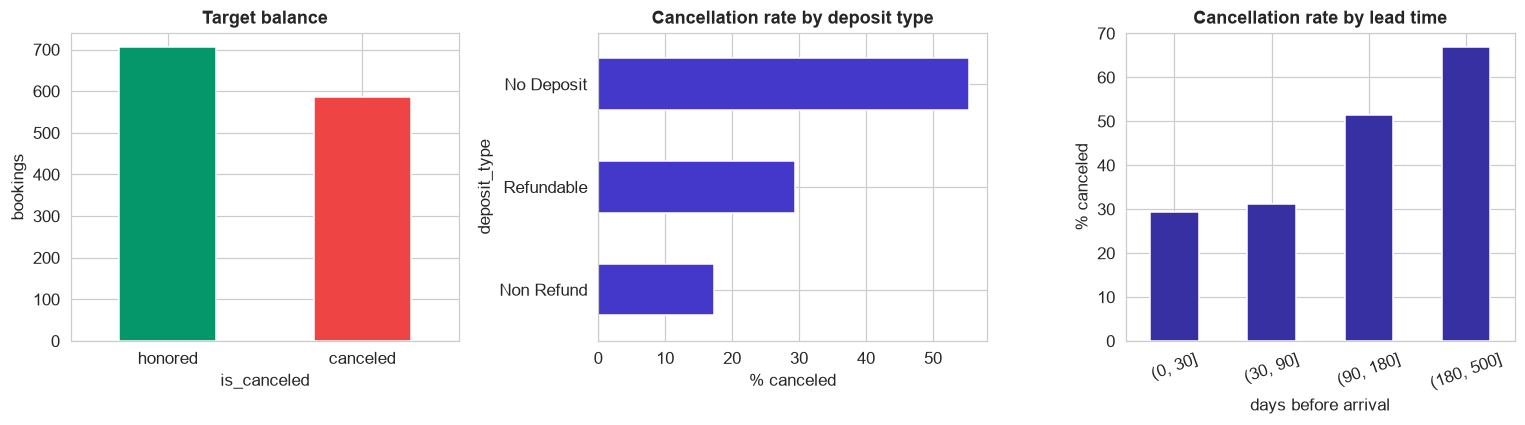

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14,4))
df.is_canceled.value_counts().rename({0:'honored',1:'canceled'}).plot.bar(ax=ax[0], color=[GREEN, RED])
ax[0].set(title='Target balance', ylabel='bookings'); ax[0].tick_params(axis='x', rotation=0)
(df.groupby('deposit_type').is_canceled.mean()*100).sort_values().plot.barh(ax=ax[1], color=EM)
ax[1].set(title='Cancellation rate by deposit type', xlabel='% canceled')
df.groupby(pd.cut(df.lead_time, [0,30,90,180,500])).is_canceled.mean().mul(100).plot.bar(ax=ax[2], color=DEEP)
ax[2].set(title='Cancellation rate by lead time', ylabel='% canceled', xlabel='days before arrival'); ax[2].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Where cancellations come from.** Cancellations are common but not the majority (a real baseline to beat). The risk climbs steeply with **lead time** (a booking made six months out is far likelier to fall through than a last-minute one) and depends strongly on **deposit type**. Guests who put money down (`Non Refund`) rarely cancel, while `No Deposit` bookings are the riskiest. This is exactly the kind of separable structure a model can learn.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 6 &#183; TRANSFORM (LEAKAGE-FREE)</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Build the preprocessing into a pipeline</div>
<div style="color:#4a5578;margin-top:6px">Impute, scale, and encode, with each step fit on training data only.</div>
</div>

In [7]:
numeric = ['lead_time','nights','adults','children','prior_cancellations','booking_changes','adr','total_special_requests','is_repeated_guest']
categorical = ['deposit_type','market_segment','customer_type']
preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)])
print('numeric features:', len(numeric), '| categorical features:', len(categorical))
print('Every step (impute, scale, one-hot) lives INSIDE the pipeline, so it is fit on the training fold only -> no leakage.')

numeric features: 9 | categorical features: 3
Every step (impute, scale, one-hot) lives INSIDE the pipeline, so it is fit on the training fold only -> no leakage.


**Why the preprocessing lives in a pipeline.** A `ColumnTransformer` median-imputes and standardizes the numeric columns and one-hot-encodes the categoricals; wrapping it in a `Pipeline` with the model means every cross-validation fold **re-fits the preprocessing on just its own training data**. Impute or scale *before* splitting and the median/mean is computed from rows that later sit in the test set, a subtle **data leak** that makes your model look better than it really is. The pipeline makes leakage almost impossible by construction.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 7 &#183; ANALYZE + SPLIT</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Train / validation / test</div>
<div style="color:#4a5578;margin-top:6px">Quarantine a test set before doing anything else.</div>
</div>

In [8]:
X = df[numeric + categorical]; y = df['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0, stratify=y)
print('training set:', X_train.shape[0], 'bookings   (used to fit AND tune the model)')
print('test set    :', X_test.shape[0], 'bookings   (LOCKED AWAY until the very end)')
print('\nThe three roles:')
print('  TRAIN      -> fit model parameters')
print('  VALIDATION -> compare models & pick hyperparameters (here: k-fold CV inside the training set)')
print('  TEST       -> one honest, final estimate of real-world performance (used ONCE)')

training set: 1032 bookings   (used to fit AND tune the model)
test set    : 259 bookings   (LOCKED AWAY until the very end)

The three roles:
  TRAIN      -> fit model parameters
  VALIDATION -> compare models & pick hyperparameters (here: k-fold CV inside the training set)
  TEST       -> one honest, final estimate of real-world performance (used ONCE)


**The golden rule of honest evaluation.** We immediately set aside **20% as a test set** and do not look at it again until the end. Model comparison and tuning happen on the training set only. Rather than carving off a single fixed *validation* set, we use **k-fold cross-validation** on the training data, which plays the validation role but rotates through the data, giving a more stable estimate and using every row. The test set is saved for the final judgment.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 8 &#183; BUILD A BASELINE + CANDIDATES</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Never trust a model without a baseline</div>
<div style="color:#4a5578;margin-top:6px">Compare three models by cross-validation.</div>
</div>

baseline (always predict the majority class) test accuracy = 0.544
Logistic Regression    5-fold CV AUC = 0.812 (+/- 0.039)


Random Forest          5-fold CV AUC = 0.789 (+/- 0.033)


Gradient Boosting      5-fold CV AUC = 0.789 (+/- 0.029)


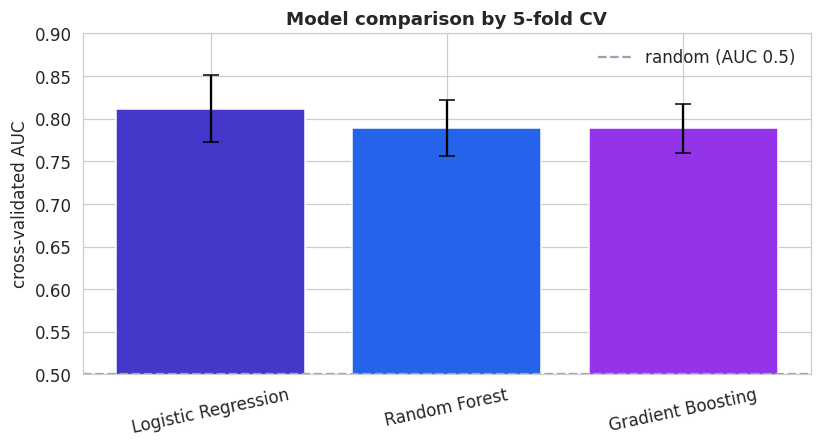

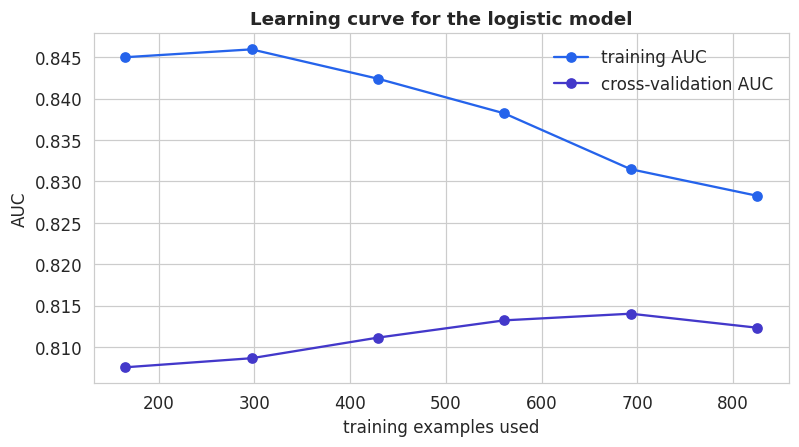

In [9]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('baseline (always predict the majority class) test accuracy = %.3f' % accuracy_score(y_test, baseline.predict(X_test)))
candidates = {'Logistic Regression': LogisticRegression(max_iter=3000),
              'Random Forest': RandomForestClassifier(random_state=0),
              'Gradient Boosting': GradientBoostingClassifier(random_state=0)}
cv_results = {}
for name, clf in candidates.items():
    pipe = Pipeline([('prep', preprocess), ('clf', clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='roc_auc')
    cv_results[name] = scores
    print(f'{name:22s} 5-fold CV AUC = {scores.mean():.3f} (+/- {scores.std():.3f})')
fig, ax = plt.subplots(figsize=(7.6,4.2))
ax.bar(cv_results.keys(), [s.mean() for s in cv_results.values()], yerr=[s.std() for s in cv_results.values()], color=[EM, BLUE, PUR], capsize=5)
ax.axhline(0.5, color=GREY, ls='--', label='random (AUC 0.5)'); ax.set(ylabel='cross-validated AUC', title='Model comparison by 5-fold CV', ylim=(0.5,0.9)); ax.legend()
plt.xticks(rotation=12); plt.tight_layout(); plt.show()
# learning curve: would more data (or a more flexible model) help?
sizes, tr_sc, va_sc = learning_curve(Pipeline([('prep',preprocess),('clf',LogisticRegression(max_iter=3000,C=0.3))]),
    X_train, y_train, cv=5, scoring='roc_auc', train_sizes=np.linspace(0.2,1.0,6), random_state=0)
fig, ax = plt.subplots(figsize=(7.4,4.2))
ax.plot(sizes, tr_sc.mean(1), 'o-', color=BLUE, label='training AUC')
ax.plot(sizes, va_sc.mean(1), 'o-', color=EM, label='cross-validation AUC')
ax.set(xlabel='training examples used', ylabel='AUC', title='Learning curve for the logistic model'); ax.legend()
plt.tight_layout(); plt.show()

**The baseline matters.** A model that always predicts 'not canceled' is already **54% accurate**, so any accuracy near that is worthless. That is why we score by **AUC** (ranking quality, baseline 0.5) and always compare against the dummy. The surprise is that **logistic regression (CV AUC 0.81) beats both tree ensembles (0.79)**. On clean, mostly-linear tabular data a well-regularized linear model is often the strongest *and* the most interpretable, so there is no reason to reach for a boosted forest by reflex. The **learning curve** confirms the choice. The training and cross-validation scores converge and flatten, so the model is not badly overfit and a lot more data would help only a little, because the ceiling here comes from the signal in the features rather than the sample size.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 9 &#183; VALIDATE BY TUNING AND THEN TESTING ONCE</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Tune on CV and judge once on the test set</div>
<div style="color:#4a5578;margin-top:6px">GridSearchCV picks the regularization; the test set gives the verdict.</div>
</div>

best regularization C = 0.3 | best CV AUC = 0.812


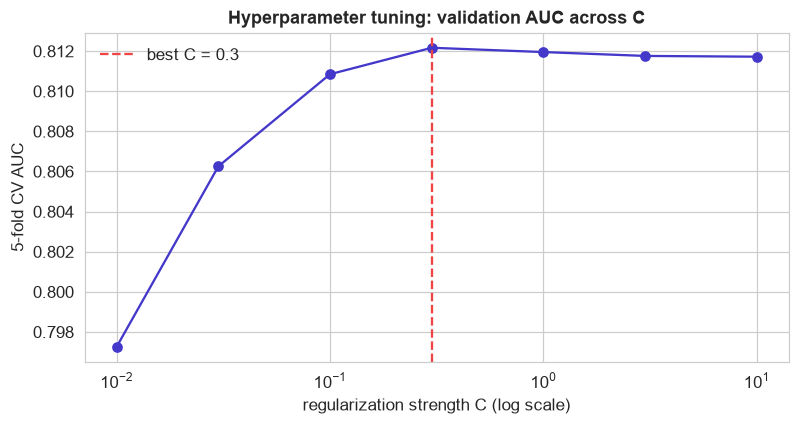


=== FINAL held-out TEST performance ===
accuracy  0.753
ROC-AUC   0.846
precision 0.718 | recall 0.754 | F1 0.736


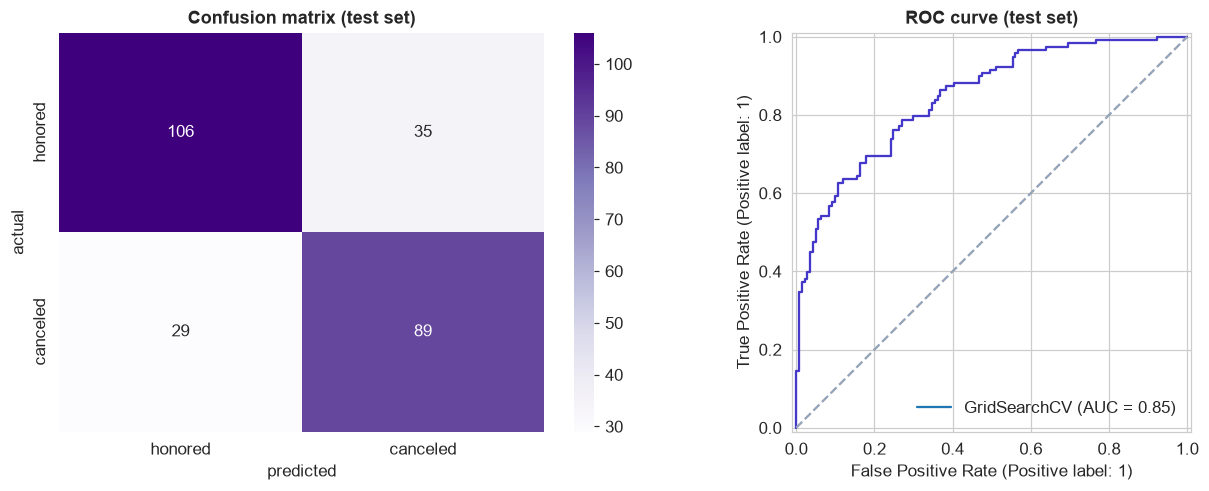

In [10]:
grid = GridSearchCV(Pipeline([('prep', preprocess), ('clf', LogisticRegression(max_iter=3000))]),
                    param_grid={'clf__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}, cv=5, scoring='roc_auc')
grid.fit(X_train, y_train)
print('best regularization C = %s | best CV AUC = %.3f' % (grid.best_params_['clf__C'], grid.best_score_))
res = pd.DataFrame(grid.cv_results_)
fig, ax = plt.subplots(figsize=(7.4,4.0))
ax.semilogx(res['param_clf__C'].astype(float), res['mean_test_score'], 'o-', color=EM)
ax.axvline(grid.best_params_['clf__C'], color=RED, ls='--', label=f"best C = {grid.best_params_['clf__C']}")
ax.set(xlabel='regularization strength C (log scale)', ylabel='5-fold CV AUC', title='Hyperparameter tuning: validation AUC across C'); ax.legend()
plt.tight_layout(); plt.show()
# --- the moment of truth: evaluate ONCE on the locked-away test set ---
y_pred = grid.predict(X_test); y_prob = grid.predict_proba(X_test)[:,1]
print('\n=== FINAL held-out TEST performance ===')
print('accuracy  %.3f' % accuracy_score(y_test, y_pred))
print('ROC-AUC   %.3f' % roc_auc_score(y_test, y_prob))
print('precision %.3f | recall %.3f | F1 %.3f' % (precision_score(y_test,y_pred), recall_score(y_test,y_pred), f1_score(y_test,y_pred)))
fig, ax = plt.subplots(1, 2, figsize=(12,4.6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=['honored','canceled'], yticklabels=['honored','canceled'], ax=ax[0])
ax[0].set(title='Confusion matrix (test set)', xlabel='predicted', ylabel='actual')
RocCurveDisplay.from_estimator(grid, X_test, y_test, ax=ax[1])
ax[1].lines[0].set_color(EM); ax[1].plot([0,1],[0,1],'--',color=GREY); ax[1].set_title('ROC curve (test set)')
plt.tight_layout(); plt.show()

**Reading the verdict.** Tuning nudged the regularization to **C = 0.3**. On the untouched test set the model scores **AUC 0.85** and **75% accuracy**, comfortably above the 54% baseline, with **recall 0.75** (it catches three-quarters of real cancellations) at **precision 0.72**. Because we tuned only on cross-validation and touched the test set exactly once, this number is an unbiased estimate for bookings drawn the same way as these, free of the optimism that tuning on the test set would add. It rests on 259 test bookings, so it is noisy (cross-validation gave 0.81), and forecasting next month's bookings would need a split by date.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 10 &#183; INTERPRET</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">What goes with a cancellation?</div>
<div style="color:#4a5578;margin-top:6px">Read the coefficients as log-odds.</div>
</div>

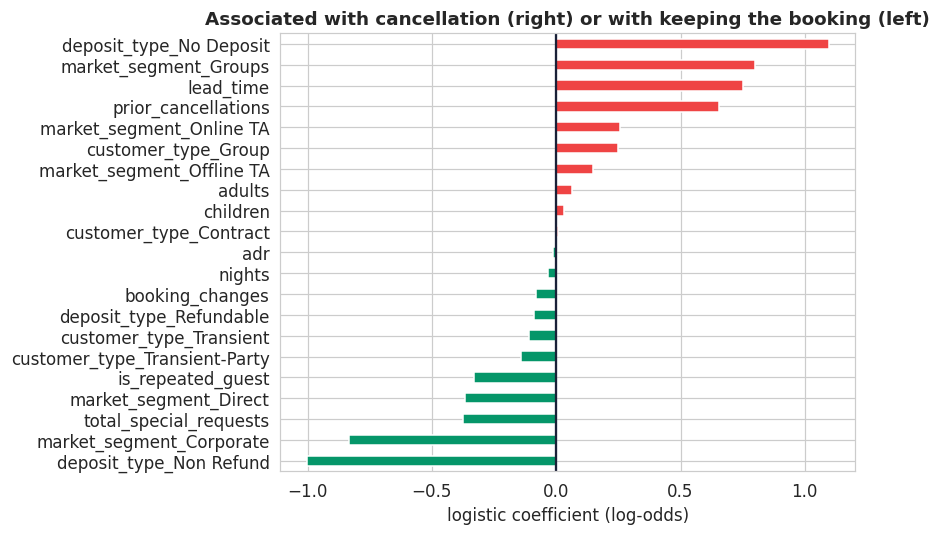

strongest cancellation signals: deposit_type_No Deposit, market_segment_Groups, lead_time
strongest keep-the-booking signals: deposit_type_Non Refund, market_segment_Corporate, total_special_requests


In [11]:
best = grid.best_estimator_
ohe = best.named_steps['prep'].named_transformers_['cat']
feat_names = numeric + list(ohe.get_feature_names_out(categorical))
coefs = pd.Series(best.named_steps['clf'].coef_[0], index=feat_names).sort_values()
fig, ax = plt.subplots(figsize=(8,5))
colors = [RED if c>0 else GREEN for c in coefs.values]
coefs.plot.barh(ax=ax, color=colors); ax.axvline(0, color=INK)
ax.set(title='Associated with cancellation (right) or with keeping the booking (left)', xlabel='logistic coefficient (log-odds)')
plt.tight_layout(); plt.show()
print('strongest cancellation signals:', ', '.join(coefs.tail(3).index[::-1]))
print('strongest keep-the-booking signals:', ', '.join(coefs.head(3).index))

**The model is legible.** Positive bars go with higher cancellation odds and negative bars with lower ones. These are associations in past bookings and say nothing about the effect of changing a policy. The numeric bars are per standard deviation while the category bars are per category, so lengths are not on one scale. The strongest risk factors are **No Deposit** bookings, **Groups**, long **lead times**, and a history of **prior cancellations**, while **Non Refund** deposits, **Corporate** bookings, and more **special requests** (a sign of genuine intent) mark reliable guests. These are the patterns built into this teaching dataset, and the model recovered them. This interpretability is *why* the simple logistic model was worth keeping.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">STEP 11 &#183; DEPLOY</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">From notebook to production</div>
<div style="color:#4a5578;margin-top:6px">Persist the whole pipeline, then serve, monitor, and retrain.</div>
</div>

In [12]:
import joblib
joblib.dump(best, 'cancellation_model.joblib')      # the ENTIRE pipeline: preprocessing + model in one object
reloaded = joblib.load('cancellation_model.joblib')
new_booking = X_test.iloc[[0]]
print('reloaded model predicts cancel-probability = %.2f for a sample booking' % reloaded.predict_proba(new_booking)[0,1])
print('\nProduction checklist: serve behind an API (predict_proba) | log inputs+scores |')
print('monitor feature DRIFT (do live bookings still look like training data?) | retrain on a schedule | keep a human in the loop for high-stakes actions')

reloaded model predicts cancel-probability = 0.68 for a sample booking

Production checklist: serve behind an API (predict_proba) | log inputs+scores |
monitor feature DRIFT (do live bookings still look like training data?) | retrain on a schedule | keep a human in the loop for high-stakes actions


**Deployment opens the next phase of work.** Saving the fitted `Pipeline` with `joblib` bundles preprocessing and model together, so production applies the *exact* same transformations as training (no skew). The model then lives behind a service that returns a cancellation probability for each new booking. The real work starts after launch, when the team watches for **data drift** (a new market segment, a price change), tracks live accuracy, and **retrains** on fresh data before performance decays. Chapter 130 is a full case study on this operational lifecycle.

## The twelve steps of the cancellation project

1. **Define** the objective as a concrete prediction.
2. **Collect** the data (CSV, SQL, API, and so on).
3. **Inspect** the shape, types, and gaps.
4. **Clean**: dedupe, fix impossible values, standardize categories.
5. **Visualize** the signal.
6. **Transform** inside a **pipeline** so preprocessing never leaks.
7. **Split** off a test set and use **cross-validation** as the validation set.
8. **Build** a **baseline** plus candidate models and compare them.
9. **Tune** with GridSearchCV, then evaluate **once** on the test set.
10. **Interpret** the drivers.
11. **Deploy** and monitor for drift.
12. **Communicate** the result in plain English.

**Trust in a model comes from the discipline of these steps more than from the choice of algorithm.**

---
<div style="text-align:center;color:#8b94b3;font-size:12px;margin-top:10px">Statistics, Data Science and AI: A Visual Handbook · © 2026 John Fisher</div>